# Predicting English Grammar Proficiency and Native Language

## Introduction
**Problem statement.** We use a large online English grammar quiz to answer two questions about adult English learners:
1. **Task 1: Proficiency prediction.** Can a learner's language background (when they started English, time spent in English-speaking countries, native language, education, etc.) predict whether they reach near-native grammar proficiency?
2. **Task 2: Native-language prediction.** Can the pattern of grammar questions a learner answers right or wrong predict their native language?

**Dataset.** Hartshorne, Tenenbaum & Pinker (2018), *A critical period for second language acquisition: Evidence from 2/3 million English speakers*, `data.csv` and `compiled.csv` from [osf.io/pyb8s](https://osf.io/pyb8s).
About 670,000 participants took an online quiz with 132 grammar questions and answered questions about their language background. The authors scored each person on 95 of the questions, the ones native speakers reliably agree on.

**Notebook outline**
- **Part 1:** data cleaning, exploration and feature engineering
- **Part 2:** Task 1, proficiency prediction
- **Part 3:** Task 2, native-language prediction

---

# Part 1: Data Cleaning, Exploration & Feature Engineering

**Outputs of this part**
- `clean_learners.parquet`: non-native learners with engineered background features and the `proficient` label (Task 1)
- `clean_native_lang_132.parquet`: learners with one of the 10 most common native languages, with their answers to all 132 questions (Task 2)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
log = {}   # running record of how many rows each step removes (for the writeup)

## 1. Load the data
Missing values in this file are stored as the text `NULL`, so we tell pandas to treat it as missing.

In [2]:
df = pd.read_csv("data.csv", na_values=["NULL"], low_memory=False)
log["start"] = len(df)
print(df.shape)
df.head()

(669498, 128)


,Unnamed: 0,id,date,time,gender,age,natlangs,primelangs,dyslexia,psychiatric,...,q34_6,q34_8,q35_1,q35_2,q35_4,q35_5,q35_7,q35_8,correct,elogit
0,1,2.0,2014-05-29,01:00:55,male,31,English,English,0,0,...,1,1,1,1,1,1,1,1,0.978947,3.621671
1,2,3.0,2014-05-29,01:01:03,male,30,English,English,0,1,...,1,1,1,1,1,1,1,1,1.000000,5.252273
2,3,3.0,2014-05-29,01:01:03,male,30,English,English,0,1,...,1,1,1,1,1,1,1,1,1.000000,5.252273
3,4,4.0,2014-05-29,01:01:13,male,19,English,English,0,0,...,1,1,1,1,1,0,1,1,0.905263,2.208853
4,5,5.0,2014-05-29,01:01:19,male,20,"Chinese/Mandarin, English","Chinese/Mandarin, English",0,0,...,1,1,1,1,1,0,1,1,0.947368,2.800602


## 2. Check the score column
The authors' `processing.R` script scored each person on 95 of the 132 grammar decisions: the ones native speakers reliably agreed on. Each `q` column is 1 (right) or 0 (wrong).
`correct` should equal the mean of those columns; we confirm that ourselves.

In [3]:
q_cols = [c for c in df.columns if c.startswith("q")]
print(len(q_cols), "scored questions")
print("max difference between our score and `correct`:", (df[q_cols].mean(axis=1) - df["correct"]).abs().max())

95 scored questions
max difference between our score and `correct`: 4.996003610813204e-16


## 3. Overview: missing values and columns with one value

In [4]:
meta = [c for c in df.columns if not c.startswith("q")]
overview = pd.DataFrame({
    "missing_share": df[meta].isna().mean().round(3),
    "n_unique": df[meta].nunique(),
}).sort_values("missing_share", ascending=False)
overview

,missing_share,n_unique
Ir_region,0.982,330
Can_region,0.926,214
UK_constituency,0.861,7300
UK_region,0.855,28
US_region,0.747,4584
Ebonics,0.747,3
Lived_Eng_per,0.449,1431
Eng_country_yrs,0.432,89
house_Eng,0.432,2
type,0.406,54


## 4. Remove duplicates and uninformative columns
- **Duplicate participant IDs:** keep the first attempt.
- **Constant columns** (same value for everyone): `dictionary`, `dyslexia`, `already_participated`.
- **Admin columns:** row index, date, time, `tests`.
- **Region columns:** 75–98% missing and only apply to specific countries.
- **`type`:** 33% missing among learners and duplicates the native-language information.

In [5]:
n0 = len(df)
df = df.drop_duplicates("id", keep="first")
log["duplicates_removed"] = n0 - len(df)

drop_cols = ["Unnamed: 0", "date", "time", "tests", "dictionary", "dyslexia", "already_participated",
             "Ir_region", "Can_region", "UK_region", "UK_constituency", "US_region", "Ebonics", "type"]
df = df.drop(columns=drop_cols)
print("duplicates removed:", log["duplicates_removed"])
print("shape now:", df.shape)

duplicates removed: 5
shape now: (669493, 114)


## 5. Sanity checks on ages
`processing.R` already removed impossible rows (starting age after current age, children reporting university degrees, ages outside 7–89). We verify that.

In [6]:
print("Eng_start > age:", (df.Eng_start > df.age).sum())
print("age range:", df.age.min(), "-", df.age.max())
print("Eng_country_yrs > age:", (df.Eng_country_yrs > df.age).sum())

Eng_start > age: 0
age range: 7 - 89
Eng_country_yrs > age: 0


## 6. Define the proficiency label
We use the score distribution of **monolingual native English speakers** (`Eng_little == "monoeng"`) as the benchmark.
A learner is **proficient** if they score at or above the **25th percentile** of native speakers.
The 10th percentile was too lenient: it would label about 61% of learners proficient, because native scores are bunched near the top.

10th percentile of native scores: 0.9263
25th percentile of native scores: 0.9579
50th percentile of native scores: 0.9789


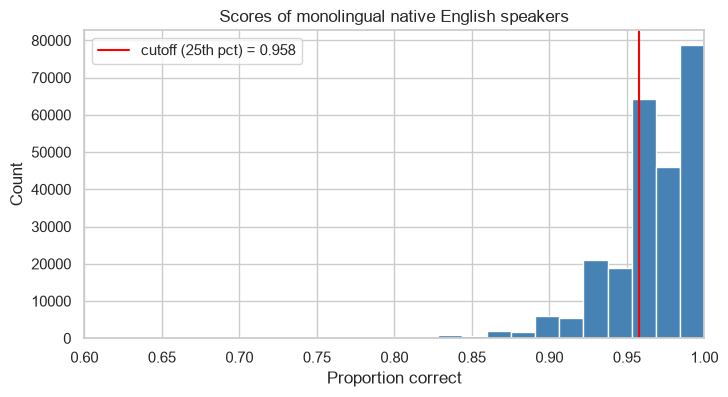

In [7]:
native = df.loc[df.Eng_little == "monoeng", "correct"]
for p in [0.10, 0.25, 0.50]:
    print(f"{int(p*100)}th percentile of native scores: {native.quantile(p):.4f}")
cutoff = native.quantile(0.25)

plt.figure(figsize=(8, 4))
plt.hist(native, bins=60, color="steelblue")
plt.axvline(cutoff, color="red", label=f"cutoff (25th pct) = {cutoff:.3f}")
plt.xlim(0.6, 1.0)
plt.xlabel("Proportion correct"); plt.ylabel("Count")
plt.title("Scores of monolingual native English speakers")
plt.legend(); plt.show()

## 7. Build the learner dataset
Learners are people who don't list English as a native language (`nat_Eng == 0`).
We also drop people with `nat_Eng == 0` but `speaker_cat == "native"`: they started English at birth without listing it as native, so it's ambiguous which group they belong to.

In [8]:
n_nonnative = (df.nat_Eng == 0).sum()
learners = df[(df.nat_Eng == 0) & (df.speaker_cat != "native")].copy()
log["ambiguous_native_removed"] = n_nonnative - len(learners)
learners["proficient"] = (learners.correct >= cutoff).astype(int)

print("learners:", len(learners), "| ambiguous rows removed:", log["ambiguous_native_removed"])
print("proficient share:", round(learners.proficient.mean(), 3))

learners: 355805 | ambiguous rows removed: 22060
proficient share: 0.365


## 8. Clean education into an ordered scale
Over 99.9% of learners chose one of the 7 English options. About 350 entries are machine-translated or garbled-character versions in other languages.
Since they're so few, we drop them rather than guess at translations.

In [9]:
edu_map = {
    "Didn't Finish High School (less than 13 years ed)": 1,
    "Haven't Finished High School (less than 13 years ed)": 1,
    "High School Degree (12-13 years)": 2,
    "Some Undergrad (higher ed)": 3,
    "Undergraduate Degree (3-5 years higher ed)": 4,
    "Some Graduate School": 5,
    "Graduate Degree": 6,
}
learners["education_level"] = learners.education.map(edu_map)
log["education_unmapped_removed"] = learners.education_level.isna().sum()
learners = learners.dropna(subset=["education_level"])
learners["education_level"] = learners.education_level.astype(int)
print("rows removed (non-English education entries):", log["education_unmapped_removed"])
learners.education_level.value_counts().sort_index()

rows removed (non-English education entries): 307


education_level
1     13276
2     48083
3     34360
4     78304
5     30946
6    150529
Name: count, dtype: int64

## 9. Missing values
Among learners, only a few background columns have missing values:
- `Eng_country_yrs` and `house_Eng` are missing for the same ~3% of people. We fill both with the median (0) and add a `background_missing` flag, so the model can tell if missingness itself means something.
- `natlangs` (2%): native language unknown. We keep these rows for Task 1, labeled `"Unknown"`.

In [10]:
print(learners[["Eng_country_yrs", "house_Eng", "natlangs", "primelangs", "currcountry"]].isna().mean().round(3))

learners["background_missing"] = (learners.Eng_country_yrs.isna() | learners.house_Eng.isna()).astype(int)
for c in ["Eng_country_yrs", "house_Eng"]:
    learners[c] = learners[c].fillna(learners[c].median())
learners["natlangs"] = learners.natlangs.fillna("Unknown")
learners["primelangs"] = learners.primelangs.fillna("Unknown")

Eng_country_yrs    0.033
house_Eng          0.033
natlangs           0.021
primelangs         0.021
currcountry        0.046
dtype: float64


## 10. Feature engineering
| Feature | Meaning |
|---|---|
| `years_exposure` | age − age started English |
| `start_age_group` | starting-age groups: 0–3, 4–7, 8–12, 13–17, 18+ (critical-period idea) |
| `lived_eng_share` | fraction of their English-learning years spent in an English-speaking country |
| `n_native_langs`, `n_prime_langs` | number of native / current primary languages listed |
| `prime_Eng` | English is one of their current primary languages (rebuilt: the original flag was 0 for every learner) |
| `lives_eng_country` | currently lives in a mainly English-speaking country |
| `native_lang_grp` | first-listed native language; the 15 most common kept, others grouped as "Other" (missing kept as "Unknown") |
| `lang_family` | language family of the first-listed native language |

In [11]:
learners["years_exposure"] = learners.age - learners.Eng_start
learners["start_age_group"] = pd.cut(learners.Eng_start, bins=[-1, 3, 7, 12, 17, 200],
                                     labels=["0-3", "4-7", "8-12", "13-17", "18+"]).astype(str)
learners["lived_eng_share"] = np.where(learners.years_exposure > 0,
                                       learners.Eng_country_yrs / learners.years_exposure, 0).clip(0, 1)

learners["n_native_langs"] = learners.natlangs.str.count(",") + 1
learners["n_prime_langs"] = learners.primelangs.str.count(",") + 1

# The original prime_Eng flag is 0 for every learner, even though many list English as a primary language,
# so we rebuild it from primelangs.
learners["prime_Eng"] = learners.primelangs.str.contains("English").astype(int)

eng_countries = ["United States", "United Kingdom", "Canada", "Australia", "New Zealand",
                 "Ireland (Republic of)", "Singapore", "South Africa"]
learners["lives_eng_country"] = learners.currcountry.isin(eng_countries).astype(int)

learners["first_native_lang"] = learners.natlangs.str.split(",").str[0].str.strip()
top15 = learners.first_native_lang[learners.first_native_lang != "Unknown"].value_counts().head(15).index
learners["native_lang_grp"] = learners.first_native_lang.where(learners.first_native_lang.isin(top15) | (learners.first_native_lang == "Unknown"), "Other")

family = {
    "Finnish": "Uralic", "Hungarian": "Uralic", "Estonian": "Uralic",
    "Turkish": "Turkic",
    "German": "Germanic", "Dutch": "Germanic", "Swedish": "Germanic", "Norwegian": "Germanic",
    "Danish": "Germanic", "Icelandic": "Germanic",
    "Spanish": "Romance", "French": "Romance", "Portuguese": "Romance", "Italian": "Romance",
    "Romanian": "Romance", "Catalan": "Romance",
    "Russian": "Slavic", "Polish": "Slavic", "Czech": "Slavic", "Ukrainian": "Slavic", "Slovak": "Slavic",
    "Serbian": "Slavic", "Croatian": "Slavic", "Bulgarian": "Slavic", "Slovenian": "Slavic",
    "Chinese/Mandarin": "Sino-Tibetan", "Chinese/Cantonese/Yue": "Sino-Tibetan",
    "Chinese/Taiwanese/Min Nan/Hokkien": "Sino-Tibetan",
    "Greek": "Hellenic", "Indonesian": "Austronesian", "Tagalog": "Austronesian", "Malay": "Austronesian",
    "Japanese": "Japonic", "Korean": "Koreanic", "Arabic": "Afro-Asiatic", "Hebrew": "Afro-Asiatic",
    "Hindi": "Indo-Iranian", "Persian/Farsi": "Indo-Iranian", "Lithuanian": "Baltic", "Latvian": "Baltic",
}
learners["lang_family"] = learners.first_native_lang.map(family).fillna("Other")

learners[["years_exposure", "start_age_group", "lived_eng_share", "n_native_langs",
          "lives_eng_country", "native_lang_grp", "lang_family"]].head()

,years_exposure,start_age_group,lived_eng_share,n_native_langs,lives_eng_country,native_lang_grp,lang_family
9,17,8-12,1.000000,2,1,Chinese/Mandarin,Sino-Tibetan
13,14,4-7,0.000000,1,0,Other,Other
14,19,18+,0.000000,1,0,Spanish,Romance
16,17,8-12,0.058824,1,0,Dutch,Germanic
17,25,4-7,1.000000,1,1,Other,Other


## 11. Exploration
### Class balance

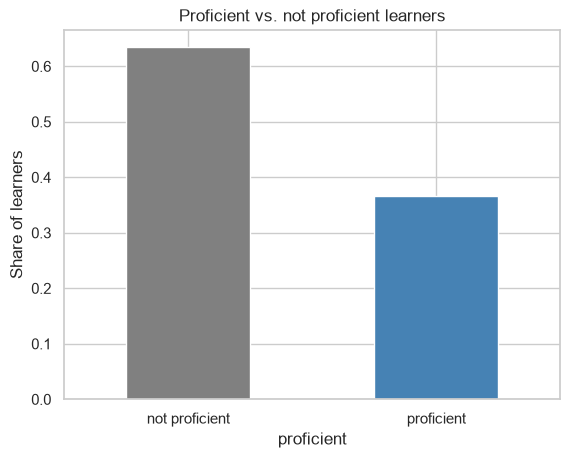

In [12]:
learners.proficient.value_counts(normalize=True).rename({0: "not proficient", 1: "proficient"}).plot.bar(color=["gray", "steelblue"])
plt.ylabel("Share of learners"); plt.title("Proficient vs. not proficient learners"); plt.xticks(rotation=0); plt.show()

### Proficiency by age started learning English

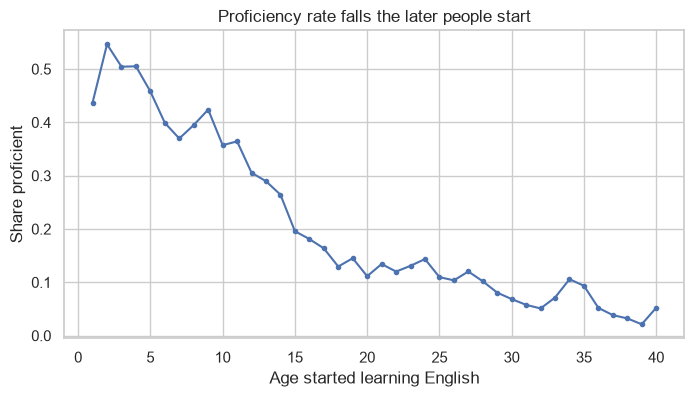

In [13]:
rate = learners[learners.Eng_start <= 40].groupby("Eng_start").proficient.mean()
plt.figure(figsize=(8, 4))
rate.plot(marker="o", ms=3)
plt.xlabel("Age started learning English"); plt.ylabel("Share proficient")
plt.title("Proficiency rate falls the later people start"); plt.show()

### Proficiency by time spent living in an English-speaking country

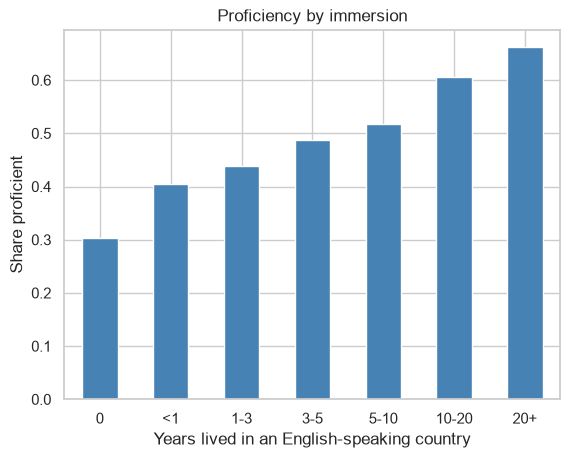

In [14]:
bins = pd.cut(learners.Eng_country_yrs, bins=[-1, 0, 1, 3, 5, 10, 20, 100],
              labels=["0", "<1", "1-3", "3-5", "5-10", "10-20", "20+"])
learners.groupby(bins, observed=True).proficient.mean().plot.bar(color="steelblue")
plt.xlabel("Years lived in an English-speaking country"); plt.ylabel("Share proficient")
plt.title("Proficiency by immersion"); plt.xticks(rotation=0); plt.show()

### Scores by native language (15 most common)

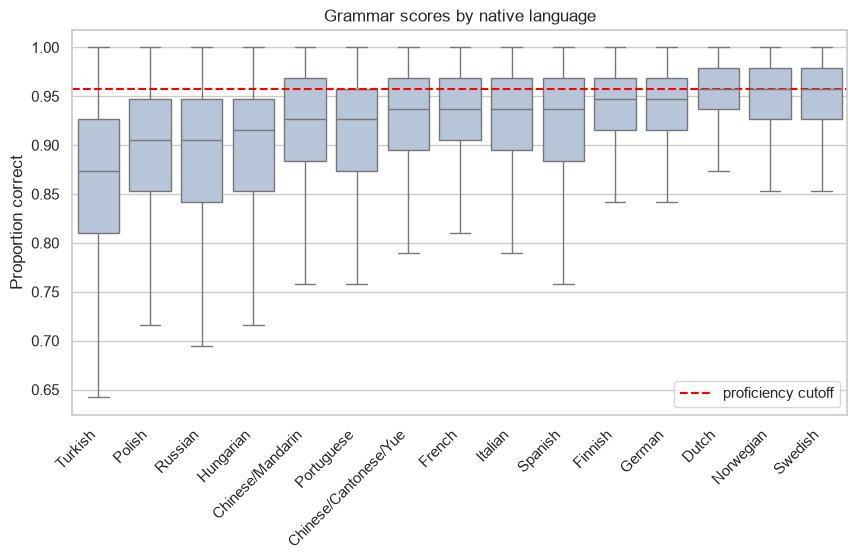

In [15]:
order = learners[~learners.native_lang_grp.isin(["Other", "Unknown"])].groupby("native_lang_grp").correct.median().sort_values().index
plt.figure(figsize=(10, 5))
sns.boxplot(data=learners[learners.native_lang_grp.isin(order)], x="native_lang_grp", y="correct",
            order=order, showfliers=False, color="lightsteelblue")
plt.axhline(cutoff, color="red", ls="--", label="proficiency cutoff")
plt.xticks(rotation=45, ha="right"); plt.xlabel(""); plt.ylabel("Proportion correct")
plt.title("Grammar scores by native language"); plt.legend(); plt.show()

### Hardest questions for learners compared with native speakers

In [16]:
gap = pd.DataFrame({
    "learners": learners[q_cols].mean(),
    "natives": df.loc[df.Eng_little == "monoeng", q_cols].mean(),
})
gap["gap"] = gap.natives - gap.learners
gap.sort_values("gap", ascending=False).head(15).round(3)

,learners,natives,gap
q34_1,0.717,0.957,0.240
q11_4,0.679,0.908,0.229
q18_3,0.775,0.947,0.172
q34_4,0.686,0.850,0.164
q24_4,0.839,0.989,0.150
q22_2,0.797,0.939,0.143
q34_6,0.801,0.942,0.141
q19_1,0.832,0.972,0.140
q13_3,0.768,0.907,0.139
q24_3,0.852,0.989,0.138


### How the numeric features relate to each other and to the label

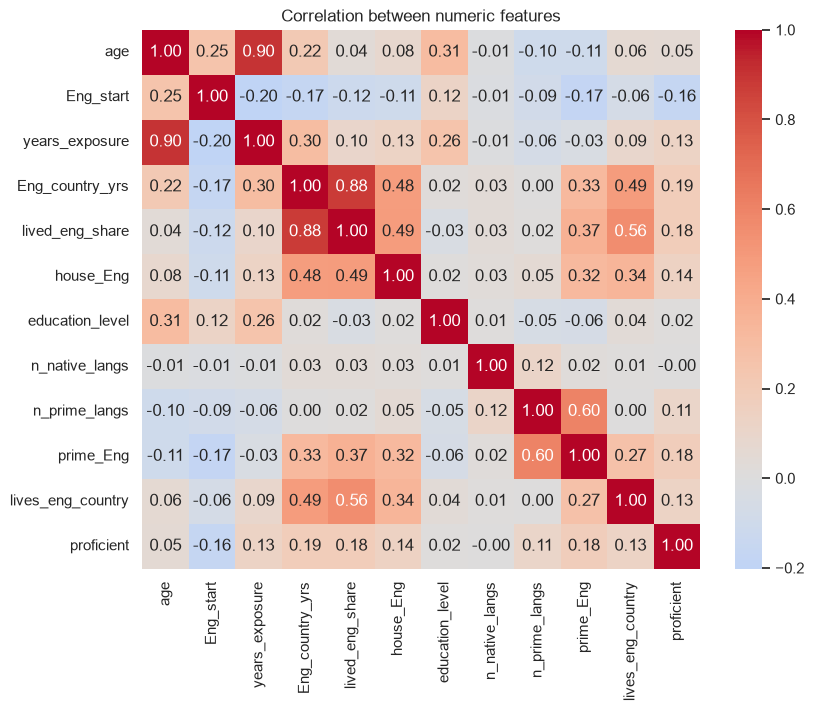

In [17]:
num = ["age", "Eng_start", "years_exposure", "Eng_country_yrs", "lived_eng_share", "house_Eng",
       "education_level", "n_native_langs", "n_prime_langs", "prime_Eng", "lives_eng_country", "proficient"]
plt.figure(figsize=(9, 7))
sns.heatmap(learners[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features"); plt.show()

## 12. Save Task 1 data (proficiency prediction)
**Model inputs:** background features only.
**Do not use as inputs:** `score` (the quiz score that defines the label), `elogit`, `Eng_little`, `speaker_cat`.

In [18]:
task1_cols = ["id", "age", "gender", "Eng_start", "years_exposure", "start_age_group", "Eng_country_yrs",
              "lived_eng_share", "house_Eng", "background_missing", "education_level", "psychiatric",
              "prime_Eng", "lives_eng_country", "n_native_langs", "n_prime_langs", "native_lang_grp",
              "lang_family", "proficient", "correct"]
task1 = learners[task1_cols].rename(columns={"correct": "score"})
task1.to_parquet("clean_learners.parquet", engine="pyarrow", compression="snappy", index=False)
print(task1.shape)
task1.head()

(355498, 20)


,id,age,gender,Eng_start,years_exposure,start_age_group,Eng_country_yrs,lived_eng_share,house_Eng,background_missing,education_level,psychiatric,prime_Eng,lives_eng_country,n_native_langs,n_prime_langs,native_lang_grp,lang_family,proficient,score
9,11.0,25,female,8,17,8-12,17.0,1.000000,0.0,0,5,0,1,1,2,1,Chinese/Mandarin,Sino-Tibetan,1,0.978947
13,15.0,20,female,6,14,4-7,0.0,0.000000,1.0,0,4,0,0,0,1,1,Other,Other,1,0.957895
14,16.0,37,male,18,19,18+,0.0,0.000000,0.0,0,6,0,0,0,1,2,Spanish,Romance,0,0.831579
16,19.0,29,female,12,17,8-12,1.0,0.058824,0.0,0,6,0,1,0,1,2,Dutch,Germanic,1,0.978947
17,1764.0,29,female,4,25,4-7,29.0,1.000000,1.0,0,6,0,1,1,1,1,Other,Other,1,0.968421


## 13. Save Task 2 data (native-language prediction)
Learners who list exactly **one** native language, restricted to the 10 most common.

**Inputs:** the 95 right/wrong columns, **plus the 37 grammar questions the original authors left out of the score** because native speakers from different English-speaking countries disagree on them (mostly American vs. British usage).
They're useless for a proficiency score, but potentially useful for Task 2: which variety of English someone learned may relate to their native language.
These come from the raw responses in `compiled.csv` (same source, osf.io/pyb8s), merged by participant `id`, and are prefixed `d_` (for "dialect"). They record which answer the person picked, not right/wrong.

In [19]:
single = learners[~learners.natlangs.str.contains(",") & (learners.natlangs != "Unknown")]
top10 = single.natlangs.value_counts().head(10).index.tolist()
task2 = single[single.natlangs.isin(top10)][["id"] + q_cols + ["natlangs"]].rename(columns={"natlangs": "native_lang"})

# Add the 37 unscored questions from the raw responses file
raw = pd.read_csv("compiled.csv", na_values=["NULL"], low_memory=False,
                  usecols=lambda c: c == "id" or c.startswith("q")).drop_duplicates("id")
extra_items = [c for c in raw.columns if c.startswith("q") and c not in q_cols]
raw = raw[["id"] + extra_items].rename(columns={c: "d_" + c for c in extra_items})
task2 = task2.merge(raw, on="id", how="left")
print("unscored questions added:", len(extra_items), "| rows missing them:", task2["d_" + extra_items[0]].isna().sum())

task2.to_parquet("clean_native_lang_132.parquet", index=False)
print("top 10 languages:", top10)
print(task2.shape)
task2.native_lang.value_counts()

unscored questions added: 37 | rows missing them: 0
top 10 languages: ['Finnish', 'Turkish', 'German', 'Russian', 'Hungarian', 'Polish', 'Dutch', 'Swedish', 'Spanish', 'Portuguese']
(223288, 134)


native_lang
Finnish       39787
Turkish       36070
German        24405
Russian       22680
Hungarian     22010
Polish        18541
Dutch         17793
Swedish       16271
Spanish       15555
Portuguese    10176
Name: count, dtype: int64

## 14. Cleaning log (row counts for the writeup)

In [20]:
log["final_task1_rows"] = len(task1)
log["final_task2_rows"] = len(task2)
log["prime_Eng_learners"] = int(task1.prime_Eng.sum())
log["cutoff"] = round(cutoff, 4)
log["proficient_share"] = round(task1.proficient.mean(), 3)
pd.Series(log)

start                         669498.0000
duplicates_removed                 5.0000
ambiguous_native_removed       22060.0000
education_unmapped_removed       307.0000
final_task1_rows              355498.0000
final_task2_rows              223288.0000
prime_Eng_learners            124821.0000
cutoff                             0.9579
proficient_share                   0.3660
dtype: float64

In [21]:
# Table 1: rows removed at each cleaning step
steps = pd.DataFrame({
    "Step": ["Raw data", "Duplicate participant IDs", "Keep non-native speakers only",
             "Ambiguous native status", "Non-English education entries",
             "Task 2: one native language, 10 most common"],
    "Rows left": [log["start"], log["start"] - log["duplicates_removed"],
                  n_nonnative, n_nonnative - log["ambiguous_native_removed"],
                  log["final_task1_rows"], log["final_task2_rows"]],
})
steps["Rows removed"] = (-steps["Rows left"].diff()).fillna(0).astype(int)
steps.loc[5, "Rows removed"] = log["final_task1_rows"] - log["final_task2_rows"]
steps[["Step", "Rows removed", "Rows left"]]

,Step,Rows removed,Rows left
0,Raw data,0,669498
1,Duplicate participant IDs,5,669493
2,Keep non-native speakers only,291628,377865
3,Ambiguous native status,22060,355805
4,Non-English education entries,307,355498
5,"Task 2: one native language, 10 most common",132210,223288


In [22]:
# Table 2: share of learners labeled proficient under each cutoff
pd.DataFrame([{"Cutoff (native percentile)": f"{int(p*100)}th",
               "Score threshold": round(native.quantile(p), 3),
               "Learners labeled proficient": f"{(task1.score >= native.quantile(p)).mean():.1%}"}
              for p in [0.10, 0.25, 0.50]])

,Cutoff (native percentile),Score threshold,Learners labeled proficient
0,10th,0.926,59.2%
1,25th,0.958,36.6%
2,50th,0.979,17.7%


# Part 2: Can we predict whether an English learner reaches near-native grammar proficiency using only their language background?

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Proprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.dummy import DummyClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

## 1. Load Data from Parquet File

In [24]:
df = pd.read_parquet("clean_learners.parquet")

print(f"Dataset shape: {df.shape}")
print(df.head())
print(df["proficient"].value_counts(normalize=True))

Dataset shape: (355498, 20)
       id  age  gender  Eng_start  years_exposure start_age_group  \
0    11.0   25  female          8              17            8-12   
1    15.0   20  female          6              14             4-7   
2    16.0   37    male         18              19             18+   
3    19.0   29  female         12              17            8-12   
4  1764.0   29  female          4              25             4-7   

   Eng_country_yrs  lived_eng_share  house_Eng  background_missing  \
0             17.0         1.000000        0.0                   0   
1              0.0         0.000000        1.0                   0   
2              0.0         0.000000        0.0                   0   
3              1.0         0.058824        0.0                   0   
4             29.0         1.000000        1.0                   0   

   education_level  psychiatric  prime_Eng  lives_eng_country  n_native_langs  \
0                5            0          1             

## 2. Define Predictor Variables and Outcome Variable
Numeric features and categorical features are separated in preparation for scaling and one-hot encoding

In [25]:
numeric_features = [
    "age", "Eng_start", "years_exposure", "Eng_country_yrs", 
    "lived_eng_share", "house_Eng", "background_missing", 
    "education_level", "psychiatric", "prime_Eng", "lives_eng_country", 
    "n_native_langs", "n_prime_langs"
]

categorical_features = [
    "gender", "start_age_group", "native_lang_grp", "lang_family"
]

X = df[numeric_features + categorical_features]
y = df["proficient"]

## 3. Split Data into Training and Test Data
We will split the dataset into 80% training data and 20% testing data. For hyperparameter tuning, we will use a stratified sample of 50,000 data points due to the size of the dataset.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=50000,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print(f"Original training set: {X_train.shape}")
print(f"Tuning sample: {X_tune.shape}")

Original training set: (284398, 17)
Tuning sample: (50000, 17)


## 4. Preprocessing Pipeline
Numerical values have to be scaled. Categorical values have to be converted to numbers via one-hot encoding. We will use ColumnTransformer to build this preprocessor.

To analyze this question, we will be using logistic regression, kNN, and decision tree to predict a participant's English proficiency. Additionally, ensembles, such as random forest and gradient boosting, will also be used. 

A pipeline will be built foreach model using the preprocessor to ensure that each model uses the same scaling and encoding process.

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}

pipelines = {
    name: Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    for name, model in models.items()
}

print("Pipelines created:")
for name in pipelines:
    print(f"- {name}")

Pipelines created:
- Logistic Regression
- KNN
- Decision Tree
- Random Forest
- Gradient Boosting


## 5. Hyperparameter Tuning
First, we define lists of hyperparamter values to test for each model.
We will be using GridSearchCV to streamline this process since many models have multiple hyperparameters.

Due to our large training data, we will tune the hyperparameters on a stratified sample set, using a 5-fold validation loop, storing the best estimators along with its parameters and F1 scores. Then, those models will be trained on the full training set.

In [28]:
# Hyperparameters to test.
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10]
    },

    "KNN": {
        "model__n_neighbors": [4, 8, 16, 32],
        "model__weights": ["uniform", "distance"],
    },

    "Decision Tree": {
        "model__max_depth": [5, 10, 20, None],
        "model__min_samples_split": [2, 10, 20],
        "model__min_samples_leaf": [1, 5, 10]
    },

    "Random Forest": {
        "model__n_estimators": [50, 100, 200],
        "model__max_depth": [10, 20, None],
        "model__min_samples_leaf": [1, 5],
    },

    "Gradient Boosting": {
        "model__n_estimators": [50, 100, 200],
        "model__learning_rate": [0.01, 0.1, 0.2],
        "model__max_depth": [2, 3, 5],
        "model__subsample": [0.8, 1.0]
    }
}

In [29]:
# Cross validation loop with stratified sample.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_models = {}
tuning_results = []

for name, pipeline in pipelines.items():

    print(f"\nTuning {name}")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring={
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        refit="f1",
        cv=cv,
        n_jobs=-1,
        verbose=1
    )
    search.fit(X_tune, y_tune)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print(f"Best F1: {search.best_score_: .4f}")
    print(f"Best parameters: {search.best_params_}")


Tuning Logistic Regression
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best F1:  0.6046
Best parameters: {'model__C': 0.1}

Tuning KNN
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best F1:  0.4981
Best parameters: {'model__n_neighbors': 32, 'model__weights': 'distance'}

Tuning Decision Tree
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best F1:  0.5926
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}

Tuning Random Forest
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best F1:  0.6111
Best parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}

Tuning Gradient Boosting
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best F1:  0.5270
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 200, 'model__subsample': 0.8}


In [30]:
# Display the best parameters.
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="Best F1",
    ascending=False
)

display(tuning_df)

,Model,Best F1,Best Parameters
3,Random Forest,0.611066,"{'model__max_depth': 20, 'model__min_samples_l..."
0,Logistic Regression,0.604590,{'model__C': 0.1}
2,Decision Tree,0.592619,"{'model__max_depth': 10, 'model__min_samples_l..."
4,Gradient Boosting,0.527046,"{'model__learning_rate': 0.1, 'model__max_dept..."
1,KNN,0.498149,"{'model__n_neighbors': 32, 'model__weights': '..."


In [31]:
# Retrain on full training set.
final_models = {}

baseline = DummyClassifier(strategy="constant", constant=1).fit(X_train, y_train)
final_models["Baseline"] = baseline

for name, best_model in best_models.items():
    final_model = clone(best_model)
    final_model.fit(X_train, y_train)
    final_models[name] = final_model

## 6. Model Evaluation
We will compare the models' performance using F1, ROC-AUC, precision, and recall. Then, a confusion matrix will be made for each model.

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
4,Random Forest,0.6699,0.5355,0.7357,0.6198,0.7451
3,Decision Tree,0.6587,0.5241,0.7286,0.6096,0.7304
1,Logistic Regression,0.6596,0.5254,0.7185,0.6069,0.7305
5,Gradient Boosting,0.6980,0.6094,0.4858,0.5407,0.7493
0,Baseline,0.3658,0.3658,1.0000,0.5356,0.5000
2,KNN,0.6724,0.5634,0.4641,0.5090,0.6837


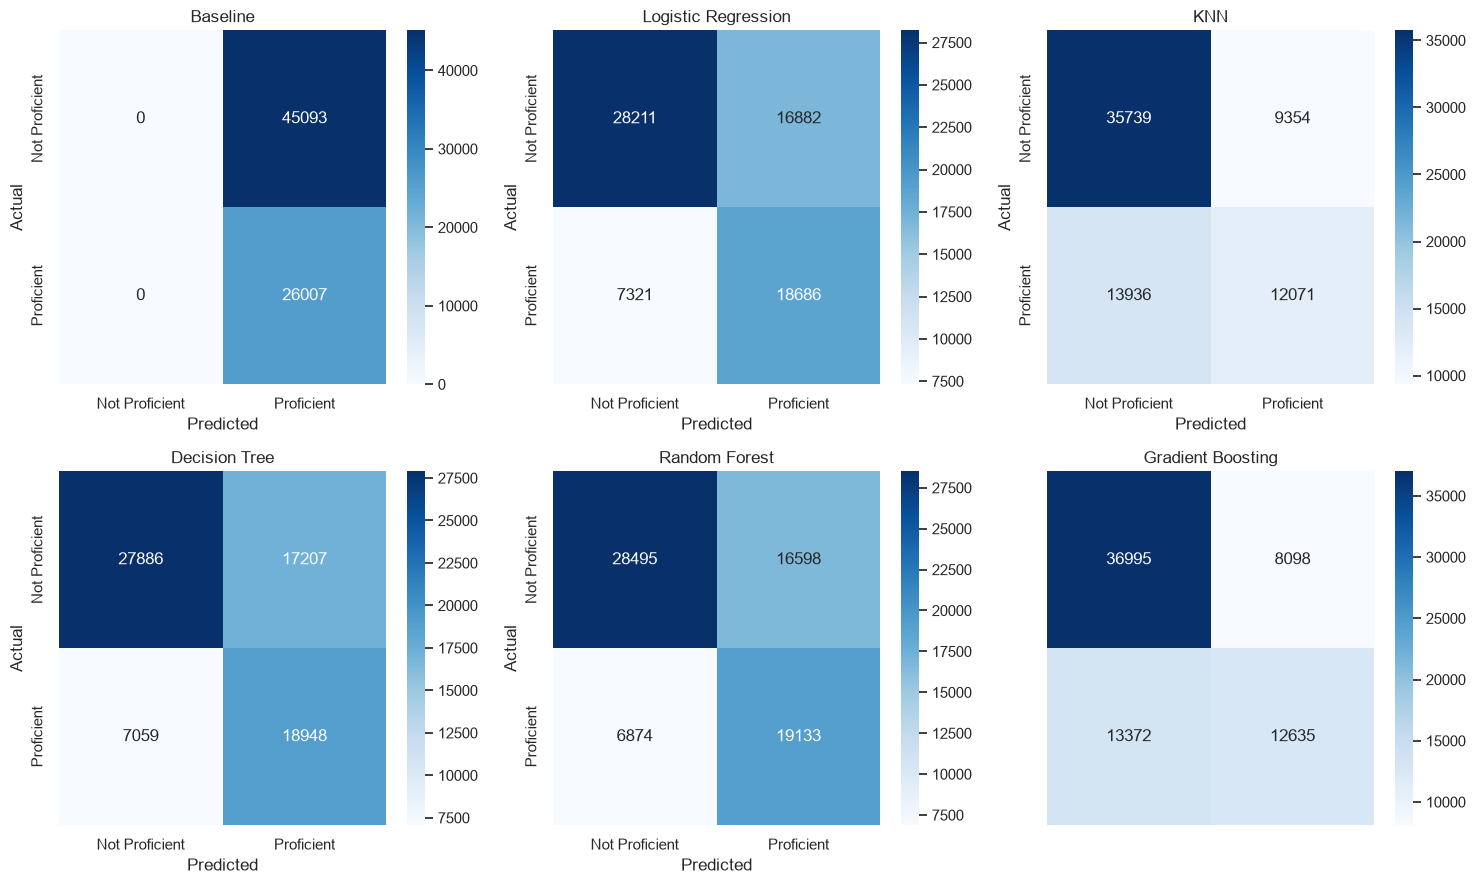

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
evaluation_results = []

for i, (name, model) in enumerate(final_models.items()):
    # Predict class labels
    y_pred = model.predict(X_test)
    # Predict probability of being proficient
    y_prob = model.predict_proba(X_test)[:, 1]

    # Scores
    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i],
        xticklabels=["Not Proficient", "Proficient"],
        yticklabels=["Not Proficient", "Proficient"]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

results_df = pd.DataFrame(evaluation_results)
results_df = results_df.sort_values(
    by="F1",
    ascending=False
)
display(results_df.round(4))

axes[-1].axis("off")
plt.tight_layout()
plt.show()

## 7. Feature Importance
Since our random forest model performed the best in terms of F1 scores and ROC/AUC, we will further analyze this model for patterns and insights, starting with feature importance.

/Users/erika/Desktop/Machine_Learning/final_project/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


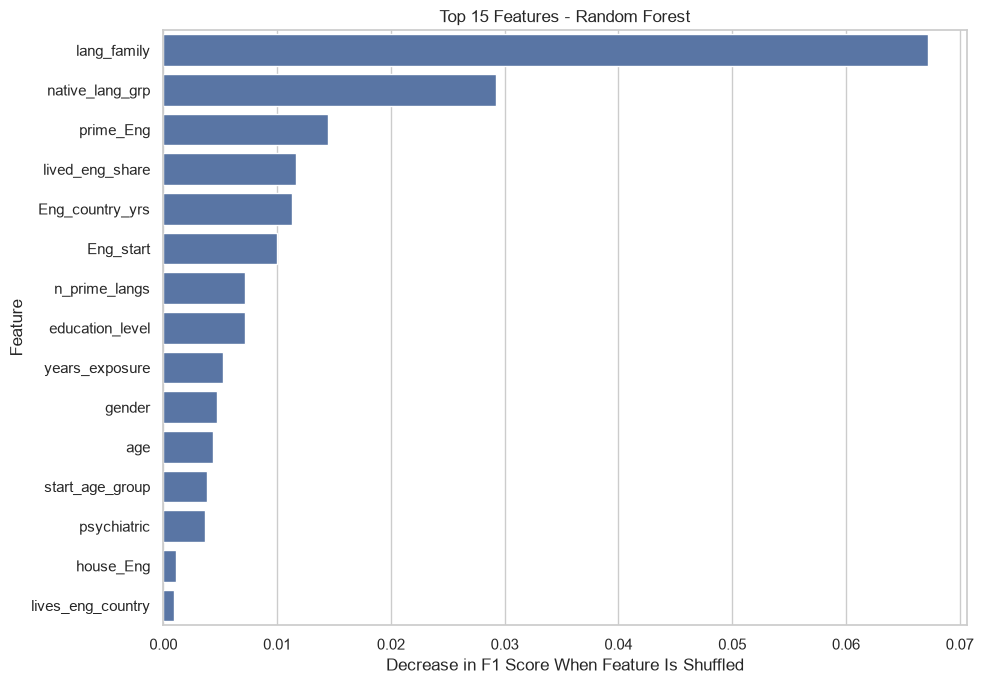

In [33]:
from sklearn.inspection import permutation_importance

rf_model = final_models["Random Forest"]

rf_importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": rf_importance.importances_mean
})

top_features = importance_df.sort_values(by="Importance",ascending=False).head(15)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Features - Random Forest")
plt.xlabel("Decrease in F1 Score When Feature Is Shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 8. Misclassification Analysis
Next, we will look at how the model misclassifies learners. Since `lang_family` is the most important feature, we can also examine whether these learners share particular language backgrounds. 

In [34]:
rf_model = final_models["Random Forest"]
y_pred = rf_model.predict(X_test)

error_analysis = X_test.copy()

error_analysis["actual"] = y_test
error_analysis["predicted"] = y_pred

# Include participant ID for identification
error_analysis["id"] = df.loc[X_test.index, "id"]

# Identify prediction errors
error_analysis["error_type"] = "Correct"
error_analysis.loc[(error_analysis["actual"] == 0) & (error_analysis["predicted"] == 1), "error_type"] = "False Positive"
error_analysis.loc[(error_analysis["actual"] == 1) & (error_analysis["predicted"] == 0), "error_type"] = "False Negative"

print(error_analysis["error_type"].value_counts())

error_type
Correct           47628
False Positive    16598
False Negative     6874
Name: count, dtype: int64


error_type,Correct,False Negative,False Positive
age,28.984,28.475,30.228
Eng_start,9.736,9.755,8.374
years_exposure,19.248,18.720,21.854
Eng_country_yrs,2.723,0.721,3.732
lived_eng_share,0.117,0.044,0.156
house_Eng,0.137,0.063,0.183
background_missing,0.036,0.037,0.021
education_level,4.470,4.475,4.404
psychiatric,0.035,0.027,0.017
prime_Eng,0.335,0.220,0.462


error_type,Correct,False Negative,False Positive
native_lang_grp,,,
Chinese/Cantonese/Yue,0.684,0.106,0.210
Chinese/Mandarin,0.774,0.096,0.130
Dutch,0.578,0.011,0.412
Finnish,0.534,0.041,0.425
French,0.647,0.143,0.209
German,0.576,0.047,0.377
Hungarian,0.751,0.181,0.068
Italian,0.680,0.170,0.150
Norwegian,0.532,0.023,0.446


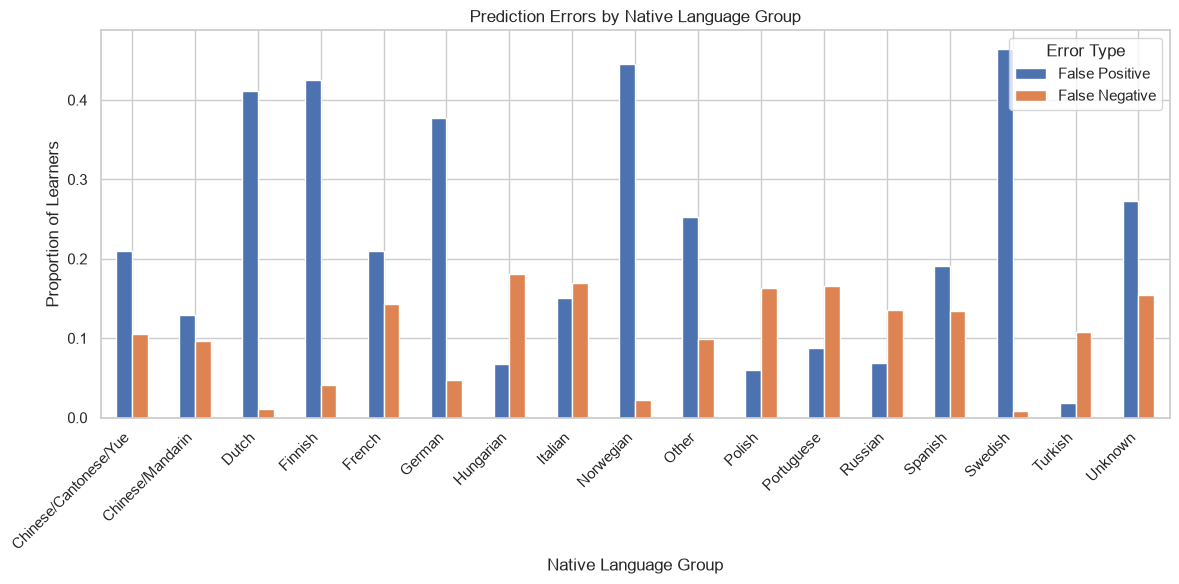

In [35]:
# Compare language background characteristics
numeric_comparison = error_analysis.groupby(
    "error_type"
)[numeric_features].mean().T
display(numeric_comparison.round(3))

# Compare native language background specifically
language_errors = pd.crosstab(
    error_analysis["native_lang_grp"],
    error_analysis["error_type"],
    normalize="index"
)
display(language_errors.round(3))

language_errors[["False Positive", "False Negative"]].plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title("Prediction Errors by Native Language Group")
plt.xlabel("Native Language Group")
plt.ylabel("Proportion of Learners")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Error Type")
plt.tight_layout()
plt.show()

In [36]:
# Actual vs. predicted proficiency rate within each language group
lang_rates = error_analysis.groupby("native_lang_grp").agg(
    n=("actual", "size"),
    actual_proficient=("actual", "mean"),
    predicted_proficient=("predicted", "mean"),
)
# Recall: share of truly proficient learners in each group that the model catches
lang_rates["recall"] = error_analysis[error_analysis["actual"] == 1].groupby("native_lang_grp")["predicted"].mean()

display(lang_rates.sort_values("actual_proficient").round(3))

,n,actual_proficient,predicted_proficient,recall
native_lang_grp,,,,
Turkish,7047,0.126,0.037,0.144
Russian,5183,0.226,0.159,0.400
Polish,3766,0.235,0.131,0.307
Hungarian,4532,0.242,0.128,0.250
Portuguese,2014,0.256,0.177,0.351
Chinese/Mandarin,2034,0.341,0.375,0.718
Spanish,3241,0.345,0.402,0.610
Italian,1784,0.358,0.338,0.525
French,2349,0.395,0.461,0.637


The random forest model correctly classified 47,721 learners, while producing 16,325 false positives and 7,054 false negatives. This indicates that the model was more likely to overestimate proficiency than underestimate it. This is expected with class_weight="balanced", which makes the model more willing to predict the smaller "proficient" class.

Comparisons of learner characteristics revealed differences between correctly and incorrectly classified individuals. False-negative learners generally had less English exposure, fewer years living in an English-speaking country, and lower levels of English use at home. In contrast, false-positive learners tended to have greater English exposure and more frequent English use at home. This suggests that although language background characteristics provide useful predictive information, they do not fully explain individual differences in grammar proficiency.

Prediction errors also varied across native-language groups. For example, Swedish, Norwegian, Finnish, and Dutch learners had relatively high proportions of false-positive predictions in the test set. These patterns suggest that the relationship between language background and grammar proficiency may differ across language groups. The table above accounts for group sizes and actual class distributions by comparing each group's actual proficiency rate with the rate the model predicts. For example, the model predicts about 97% of Dutch learners as proficient when only about 57% actually are, while it catches only about 14% of proficient Turkish learners (recall). This suggests the model relies heavily on native-language group averages rather than individual background, which would be unfair to proficient learners from lower-scoring language groups.

# Part 3: Can we predict a learner's native language from which grammar questions they get right or wrong?

If learners from different language backgrounds make different kinds of grammar mistakes, a model should be able to guess a learner's native language from their answers alone. We test this on learners whose single native language is one of the 10 most common in the dataset.

In [37]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TUNE_SIZE = 50_000

## 1. Load Data from Parquet File
This file contains learners who list exactly one native language, restricted to the 10 most common languages. Each row has:
- **95 scored questions** (`q...`): the grammar decisions the original authors used to compute the overall score, where native speakers reliably agree. 1 = right, 0 = wrong.
- **37 extra questions** (`d_q...`): the remaining grammar decisions the authors left out of the score because native speakers disagree on them. Like the scored questions, each is coded 0 or 1.
- `native_lang`: the outcome we want to predict.

In [38]:
# Use the version of the file that includes the 37 d_q columns.
DATA_FILE = "clean_native_lang_132.parquet"

df = pd.read_parquet(DATA_FILE)

print(f"Dataset shape: {df.shape}")
print(df["native_lang"].value_counts())

Dataset shape: (223288, 134)
native_lang
Finnish       39787
Turkish       36070
German        24405
Russian       22680
Hungarian     22010
Polish        18541
Dutch         17793
Swedish       16271
Spanish       15555
Portuguese    10176
Name: count, dtype: int64


## 2. Define Predictor Variables and Outcome Variable
We keep the two groups of questions separate so we can compare models trained on the 95 scored questions alone against models trained on all 132.

In [39]:
q_cols = [c for c in df.columns if c.startswith("q")]      # 95 scored questions
d_cols = [c for c in df.columns if c.startswith("d_q")]    # 37 extra questions
all_cols = q_cols + d_cols

print(f"Scored questions: {len(q_cols)} | extra questions: {len(d_cols)} | total: {len(all_cols)}")
print("Missing values in any question column:", int(df[all_cols].isna().sum().sum()))
print("Values in question columns:", sorted(pd.unique(df[all_cols].values.ravel())))

X = df[all_cols].astype(int)
y = df["native_lang"]
languages = sorted(y.unique())

Scored questions: 95 | extra questions: 37 | total: 132
Missing values in any question column: 0
Values in question columns: [np.float64(0.0), np.float64(1.0)]


## 3. Data Exploration
### Class balance
The 10 languages have very different sample sizes, so we use **macro F1** (every language counts equally) as our main metric and class weights where the model supports them.

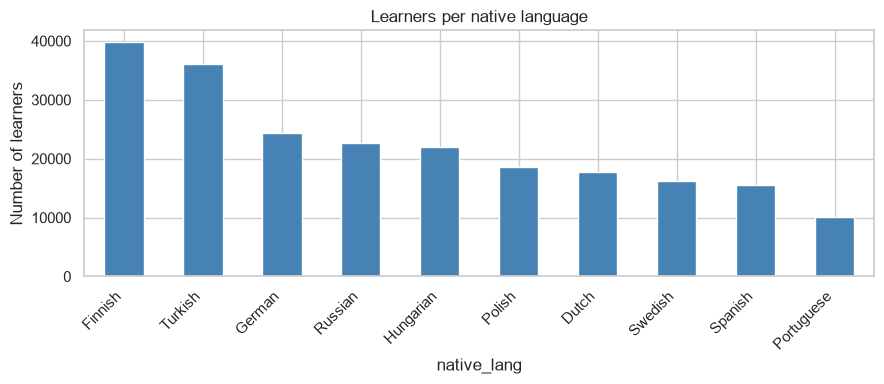

Largest / smallest class: 3.9x


In [40]:
y.value_counts().plot.bar(color="steelblue", figsize=(9, 4))
plt.ylabel("Number of learners")
plt.title("Learners per native language")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(f"Largest / smallest class: {y.value_counts().max() / y.value_counts().min():.1f}x")

### Overall score by native language
The overall score is the share of the 95 scored questions answered correctly. If some languages score much higher than others, a model could partly identify native language from *skill level* rather than from language-specific mistakes. We come back to this in Section 11.

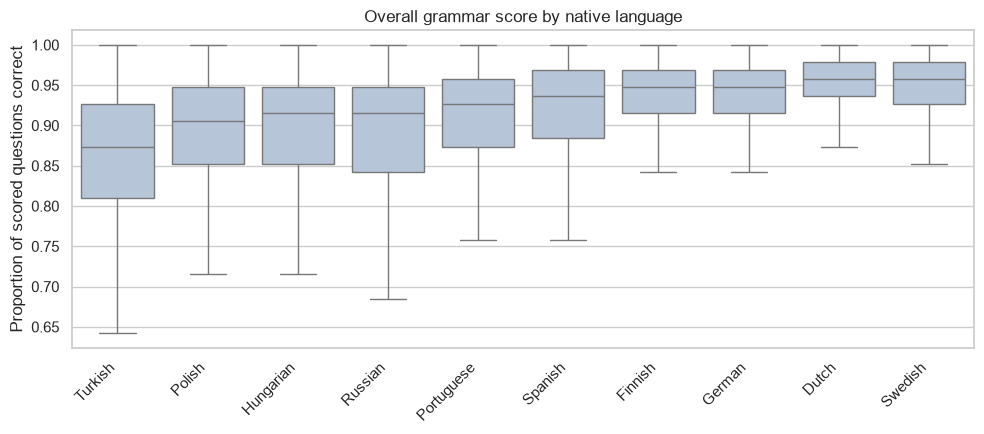

In [41]:
score = X[q_cols].mean(axis=1)

order = score.groupby(y).median().sort_values().index
plt.figure(figsize=(10, 4.5))
sns.boxplot(x=y, y=score, order=order, showfliers=False, color="lightsteelblue")
plt.xlabel("")
plt.ylabel("Proportion of scored questions correct")
plt.title("Overall grammar score by native language")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Which questions differ most between languages?
For each question, we compute the share of each language group that answered 1 (for scored questions, the correct answer), then show the 20 questions where the languages differ the most. Bright and dark cells in the same column mean that question separates languages.

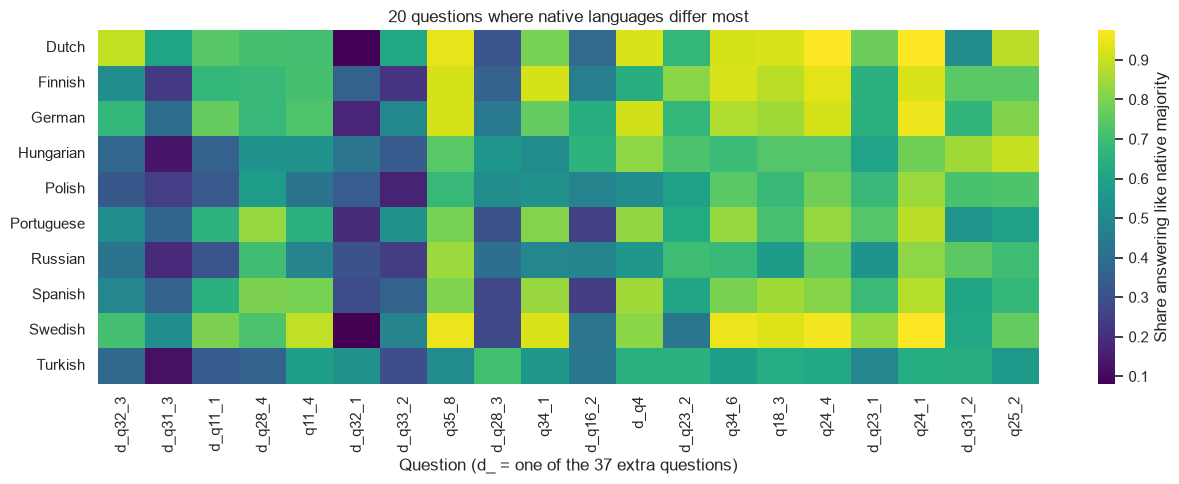

Of these 20 questions, 12 are extra (d_) questions.


In [42]:
rate_by_lang = X.groupby(y).mean()                     # languages x questions
spread = rate_by_lang.max() - rate_by_lang.min()
top_q = spread.sort_values(ascending=False).head(20).index

plt.figure(figsize=(13, 5))
sns.heatmap(rate_by_lang[top_q], cmap="viridis", annot=False, cbar_kws={"label": "Share answering like native majority"})
plt.title("20 questions where native languages differ most")
plt.xlabel("Question (d_ = one of the 37 extra questions)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Of these 20 questions,", sum(c.startswith("d_") for c in top_q), "are extra (d_) questions.")

**Result:** 12 of the 20 questions that differ most between languages are extra (`d_`) questions, an early sign that the questions native speakers disagree on carry the most native-language information.

## 4. Split Data into Training and Test Data
We split into 80% training and 20% test data, stratified by language. For hyperparameter tuning we use a stratified sample of 50,000 training rows, since the full training set is large. The test set is only used for the final evaluation.

Both feature sets (95 and 132 questions) use the **same rows** in each split, so their results are directly comparable.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=TUNE_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Tuning sample: {X_tune.shape}")

Training set: (178630, 132)
Test set: (44658, 132)
Tuning sample: (50000, 132)


## 5. Baseline
A model that always guesses the most common language (Finnish). Every real model has to beat this.

In [44]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print(f"Baseline accuracy: {accuracy_score(y_test, baseline_pred):.3f}")
print(f"Baseline macro F1: {f1_score(y_test, baseline_pred, average='macro'):.3f}")

Baseline accuracy: 0.178
Baseline macro F1: 0.030


## 6. Models and Hyperparameter Tuning
We compare five models from different families:
- **Logistic regression** (multinomial, one linear score per language)
- **Naive Bayes** (`BernoulliNB`, designed for 0/1 features)
- **Random forest** (bagging ensemble of trees)
- **Gradient boosting** (`HistGradientBoostingClassifier`, a boosting ensemble that is fast on large data)
- **MLP** (a small neural network with one or two hidden layers)

All questions are already 0/1, so no scaling or encoding is needed. Each model is tuned with GridSearchCV using 3-fold stratified cross-validation on the tuning sample, scored by macro F1. Naive Bayes and the MLP have no `class_weight` option; for Naive Bayes, `fit_prior=False` treats all languages as equally likely beforehand instead.

In [45]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000
    ),
    "Naive Bayes": BernoulliNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=300,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "MLP": MLPClassifier(
        early_stopping=True,
        max_iter=200,
        random_state=RANDOM_STATE
    )
}

# Hyperparameters to test.
param_grids = {
    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10]
    },
    "Naive Bayes": {
        "alpha": [0.01, 0.1, 1.0],
        "fit_prior": [True, False]
    },
    "Random Forest": {
        "max_depth": [None, 20],
        "min_samples_leaf": [1, 5],
        "max_features": ["sqrt", 0.3]
    },
    "Gradient Boosting": {
        "learning_rate": [0.05, 0.1],
        "max_depth": [None, 6]
    },
    "MLP": {
        "hidden_layer_sizes": [(64,), (128,), (128, 64)],
        "alpha": [1e-4, 1e-3]
    }
}

In [46]:
# Cross-validation loop on the stratified tuning sample.
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

best_models = {}
tuning_results = []

for name, model in models.items():

    print(f"\nTuning {name}")
    start = time.time()

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1
    )
    search.fit(X_tune, y_tune)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV macro F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print(f"Best CV macro F1: {search.best_score_:.4f}")
    print(f"Best parameters: {search.best_params_}")
    print(f"Time: {time.time() - start:.0f}s")


Tuning Logistic Regression
Best CV macro F1: 0.4831
Best parameters: {'C': 0.1}
Time: 13s

Tuning Naive Bayes
Best CV macro F1: 0.3977
Best parameters: {'alpha': 0.01, 'fit_prior': False}
Time: 1s

Tuning Random Forest


/Users/erika/Desktop/Machine_Learning/final_project/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best CV macro F1: 0.4528
Best parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Time: 49s

Tuning Gradient Boosting
Best CV macro F1: 0.4981
Best parameters: {'learning_rate': 0.05, 'max_depth': 6}
Time: 106s

Tuning MLP
Best CV macro F1: 0.4989
Best parameters: {'alpha': 0.001, 'hidden_layer_sizes': (128,)}
Time: 13s


In [47]:
# Display the best parameters.
tuning_df = pd.DataFrame(tuning_results).sort_values(by="Best CV macro F1", ascending=False)
display(tuning_df)

,Model,Best CV macro F1,Best Parameters
4,MLP,0.498935,"{'alpha': 0.001, 'hidden_layer_sizes': (128,)}"
3,Gradient Boosting,0.498109,"{'learning_rate': 0.05, 'max_depth': 6}"
0,Logistic Regression,0.483117,{'C': 0.1}
2,Random Forest,0.452836,"{'max_depth': 20, 'max_features': 'sqrt', 'min..."
1,Naive Bayes,0.397702,"{'alpha': 0.01, 'fit_prior': False}"


In [48]:
# Retrain each tuned model on the full training set.
final_models = {}

for name, best_model in best_models.items():
    start = time.time()
    final_model = clone(best_model)
    final_model.fit(X_train, y_train)
    final_models[name] = final_model
    print(f"{name} retrained in {time.time() - start:.0f}s")

Logistic Regression retrained in 12s
Naive Bayes retrained in 0s
Random Forest retrained in 28s
Gradient Boosting retrained in 63s
MLP retrained in 7s


## 7. Ensemble: Soft Voting
A soft-voting ensemble averages the predicted probabilities of several models, so when one model is unsure the others can outvote it. We combine the three strongest models from cross-validation.

In [49]:
top3 = tuning_df["Model"].head(3).tolist()
print("Voting ensemble uses:", top3)

voting = VotingClassifier(
    estimators=[(name, clone(best_models[name])) for name in top3],
    voting="soft",
    n_jobs=-1
)
voting.fit(X_train, y_train)
final_models["Voting Ensemble"] = voting

Voting ensemble uses: ['MLP', 'Gradient Boosting', 'Logistic Regression']


## 8. Model Evaluation
We compare the models on the test set. Macro F1 is the main metric; precision and recall are also macro-averaged over the 10 languages.

In [50]:
def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

predictions = {name: model.predict(X_test) for name, model in final_models.items()}

evaluation_results = [evaluate("Baseline (most frequent)", y_test, baseline_pred)]
evaluation_results += [evaluate(name, y_test, pred) for name, pred in predictions.items()]

results_df = pd.DataFrame(evaluation_results).sort_values(by="Macro F1", ascending=False)
display(results_df.round(4))

best_name = results_df.iloc[0]["Model"]
best_model = final_models[best_name]
best_pred = predictions[best_name]
print(f"Best model: {best_name}")

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
6,Voting Ensemble,0.5577,0.5298,0.5343,0.5308
5,MLP,0.5609,0.5418,0.5214,0.5270
4,Gradient Boosting,0.5462,0.5198,0.5330,0.5233
1,Logistic Regression,0.5160,0.4913,0.5054,0.4939
3,Random Forest,0.5020,0.4770,0.4757,0.4720
2,Naive Bayes,0.4260,0.4168,0.4077,0.3959
0,Baseline (most frequent),0.1782,0.0178,0.1000,0.0302


Best model: Voting Ensemble


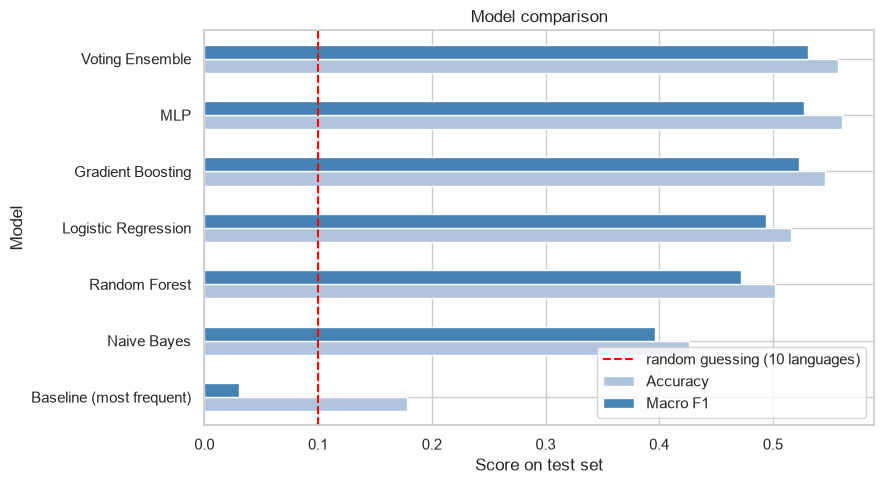

In [51]:
plot_df = results_df.set_index("Model")[["Accuracy", "Macro F1"]].sort_values("Macro F1")
plot_df.plot.barh(figsize=(9, 5), color=["lightsteelblue", "steelblue"])
plt.axvline(0.1, color="red", ls="--", label="random guessing (10 languages)")
plt.xlabel("Score on test set")
plt.title("Model comparison")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Result:** Every model beats the baseline by a wide margin. The voting ensemble is best (macro F1 0.531, accuracy 55.8%), but only slightly ahead of the MLP (0.527) and gradient boosting (0.523), so combining models added little. The MLP has the highest accuracy but lower macro F1, since it has no class weighting and leans toward the larger languages. Naive Bayes is weakest (0.396), likely because it assumes each question is independent of the others given the language.

## 9. Feature Experiments
### 9a. 95 scored questions vs. all 132 questions
The original authors removed 37 grammar decisions from the score because native speakers disagree on them. Those items capture dialect and usage variation, so they may carry native-language information that the 95 "standard" questions do not. We retrain the tuned models using only the 95 scored questions, on the same rows, and compare.

,Model,Features,Accuracy,Macro F1
0,Logistic Regression,95 scored questions,0.3972,0.3803
1,Logistic Regression,All 132 questions,0.5160,0.4939
2,Gradient Boosting,95 scored questions,0.4163,0.3971
3,Gradient Boosting,All 132 questions,0.5462,0.5233


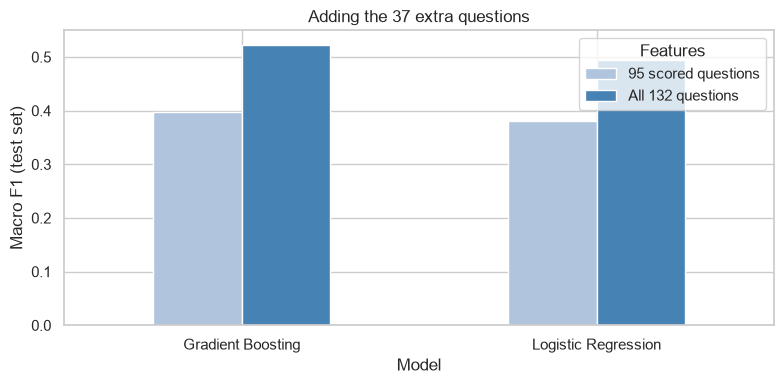

In [52]:
compare_models = ["Logistic Regression", "Gradient Boosting"]
feature_set_results = []

for name in compare_models:
    for label, cols in [("95 scored questions", q_cols), ("All 132 questions", all_cols)]:
        if cols is all_cols:
            pred = predictions[name]
        else:
            model_95 = clone(best_models[name]).fit(X_train[cols], y_train)
            pred = model_95.predict(X_test[cols])
        feature_set_results.append({
            "Model": name,
            "Features": label,
            "Accuracy": accuracy_score(y_test, pred),
            "Macro F1": f1_score(y_test, pred, average="macro")
        })

feature_set_df = pd.DataFrame(feature_set_results)
display(feature_set_df.round(4))

feature_set_df.pivot(index="Model", columns="Features", values="Macro F1").plot.bar(
    figsize=(8, 4), color=["lightsteelblue", "steelblue"])
plt.ylabel("Macro F1 (test set)")
plt.title("Adding the 37 extra questions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Result:** Adding the 37 extra questions raised macro F1 by about 0.11–0.13 for both models (logistic regression 0.380 → 0.494; gradient boosting 0.397 → 0.523). This is the largest improvement in the project: the questions left out of the score because native speakers disagree on them are the most informative about a learner's native language.

### 9b. Adding skill information
Two more ideas, compared with cross-validation on the tuning sample (not the test set):
- **+ score:** add each learner's overall score as an extra feature.
- **Skill-adjusted:** replace each answer with *(actual answer − expected answer for someone at the same skill level)*, so the model focuses on language-specific mistakes rather than on how good the learner is overall.

Both are written as scikit-learn transformers inside a pipeline, so the "expected" values are learned only from the training folds.

In [53]:
class AddScore(BaseEstimator, TransformerMixin):
    """Adds each person's overall score (share of the 95 scored questions right) as an extra column."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["score"] = X[q_cols].mean(axis=1)
        return X

class SkillAdjust(BaseEstimator, TransformerMixin):
    """Replaces each answer with (actual - expected for someone at that skill level), plus the score."""
    def __init__(self, n_bands=10):
        self.n_bands = n_bands
    def fit(self, X, y=None):
        score = X[q_cols].mean(axis=1)
        self.edges_ = np.unique(np.quantile(score, np.linspace(0, 1, self.n_bands + 1)))
        band = self._band(score)
        self.expected_ = X.groupby(band).mean().reindex(range(len(self.edges_) - 1)).fillna(X.mean())
        return self
    def _band(self, score):
        return np.clip(np.searchsorted(self.edges_, score, side="right") - 1, 0, len(self.edges_) - 2)
    def transform(self, X):
        score = X[q_cols].mean(axis=1)
        out = pd.DataFrame(X.values - self.expected_.values[self._band(score)], columns=X.columns, index=X.index)
        out["score"] = score
        return out

skill_results = []
for name in compare_models:
    base = best_models[name]
    for label, pipe in [("Plain", clone(base)),
                        ("+ score", make_pipeline(AddScore(), clone(base))),
                        ("Skill-adjusted", make_pipeline(SkillAdjust(), clone(base)))]:
        scores = cross_val_score(pipe, X_tune, y_tune, cv=cv, scoring="f1_macro", n_jobs=-1)
        skill_results.append({"Model": name, "Features": label, "CV macro F1": scores.mean()})

display(pd.DataFrame(skill_results).pivot(index="Model", columns="Features", values="CV macro F1").round(4))

Features,+ score,Plain,Skill-adjusted
Model,,,
Gradient Boosting,0.4988,0.4981,0.4911
Logistic Regression,0.4829,0.4831,0.4727


**Result:** Neither idea helped: all differences are under 0.01, and skill-adjusting was slightly worse for both models. The models already capture skill level from the answers themselves, so we kept the plain features.

## 10. Which Languages Get Confused?
Per-language results and a confusion matrix for the best model. Each row of the matrix is a true language and sums to 1: the diagonal is the share identified correctly, and bright off-diagonal cells show which languages get mixed up.

In [54]:
print(f"Classification report: {best_name}\n")
print(classification_report(y_test, best_pred, digits=3))

Classification report: Voting Ensemble

              precision    recall  f1-score   support

       Dutch      0.485     0.604     0.538      3559
     Finnish      0.675     0.641     0.658      7958
      German      0.522     0.537     0.530      4881
   Hungarian      0.514     0.511     0.513      4402
      Polish      0.513     0.473     0.492      3708
  Portuguese      0.423     0.413     0.418      2035
     Russian      0.556     0.516     0.535      4536
     Spanish      0.434     0.440     0.437      3111
     Swedish      0.483     0.565     0.521      3254
     Turkish      0.692     0.644     0.667      7214

    accuracy                          0.558     44658
   macro avg      0.530     0.534     0.531     44658
weighted avg      0.562     0.558     0.559     44658



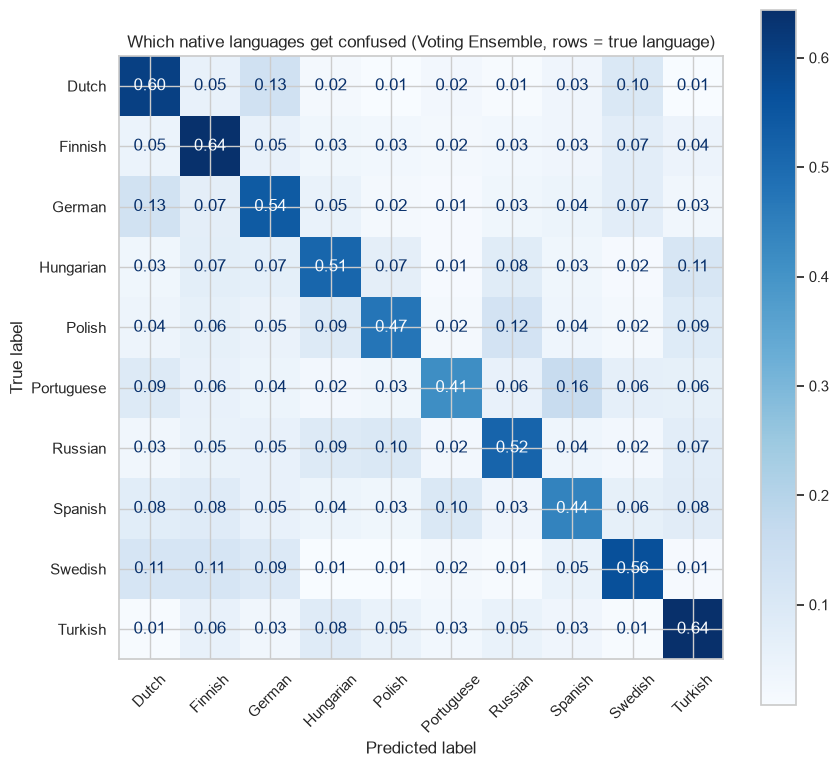

In [55]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred,
    labels=languages,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=ax,
    xticks_rotation=45
)
ax.set_title(f"Which native languages get confused ({best_name}, rows = true language)")
plt.tight_layout()
plt.show()

In [56]:
# Most common mix-ups (off-diagonal cells), as a share of the true language.
cm = pd.crosstab(y_test, best_pred, normalize="index")
mixups = cm.stack().rename("share").reset_index()
mixups.columns = ["True language", "Predicted as", "Share"]
mixups = mixups[mixups["True language"] != mixups["Predicted as"]]
display(mixups.sort_values("Share", ascending=False).head(10).round(3))

,True language,Predicted as,Share
57,Portuguese,Spanish,0.158
2,Dutch,German,0.134
20,German,Dutch,0.128
46,Polish,Russian,0.124
81,Swedish,Finnish,0.113
80,Swedish,Dutch,0.113
39,Hungarian,Turkish,0.108
75,Spanish,Portuguese,0.101
64,Russian,Polish,0.101
8,Dutch,Swedish,0.099


**Result:** The most common mix-ups are between related languages: Portuguese → Spanish (16%), Dutch ↔ German (13%), Polish → Russian (12%), and Swedish → Dutch (11%). Swedish → Finnish (11%) is an exception across families, possibly reflecting shared education or geography. Turkish and Finnish are identified best; Portuguese and Spanish, the smallest classes, are hardest.

## 11. Error Analysis: Accuracy by Learner Skill
The model identifies native language from mistakes. Learners who make very few mistakes leave little to go on, so we expect accuracy to fall as overall score rises. We split the test set into four equal groups by overall score.

,Score range,Accuracy,Macro F1
Lowest 25%,0.48-0.87,0.642,0.583
25-50%,0.87-0.93,0.585,0.570
50-75%,0.93-0.97,0.534,0.502
Top 25%,0.97-1.00,0.470,0.377


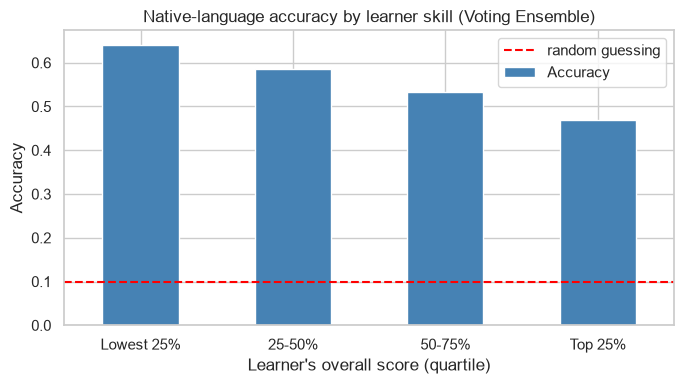

In [57]:
test_score = X_test[q_cols].mean(axis=1)
is_correct = pd.Series(best_pred == y_test.values, index=y_test.index)

skill_band = pd.qcut(test_score.rank(method="first"), 4,
                     labels=["Lowest 25%", "25-50%", "50-75%", "Top 25%"])

skill_df = pd.DataFrame({
    "Score range": test_score.groupby(skill_band, observed=True).agg(lambda s: f"{s.min():.2f}-{s.max():.2f}"),
    "Accuracy": is_correct.groupby(skill_band, observed=True).mean(),
    "Macro F1": [f1_score(y_test[skill_band == b], best_pred[(skill_band == b).values], average="macro")
                 for b in skill_band.cat.categories]
})
display(skill_df.round(3))

skill_df["Accuracy"].plot.bar(color="steelblue", figsize=(7, 4))
plt.axhline(0.1, color="red", ls="--", label="random guessing")
plt.ylabel("Accuracy")
plt.xlabel("Learner's overall score (quartile)")
plt.title(f"Native-language accuracy by learner skill ({best_name})")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

**Result:** As expected, accuracy falls from 64% for the lowest-scoring quarter to 47% for the top quarter (macro F1 0.58 → 0.38). Learners who make more mistakes give the model more to work with; near-native learners look alike regardless of native language. This explains much of why overall accuracy stays near 55%.

## 12. Feature Importance: Which Questions Reveal Native Language?
We use permutation importance on the best model: shuffle one question at a time and measure how much macro F1 drops. To keep this fast, we use a stratified sample of 10,000 test rows. Bars are colored by whether the question is one of the 95 scored questions or one of the 37 extra ones.

Permutation importance took 84s


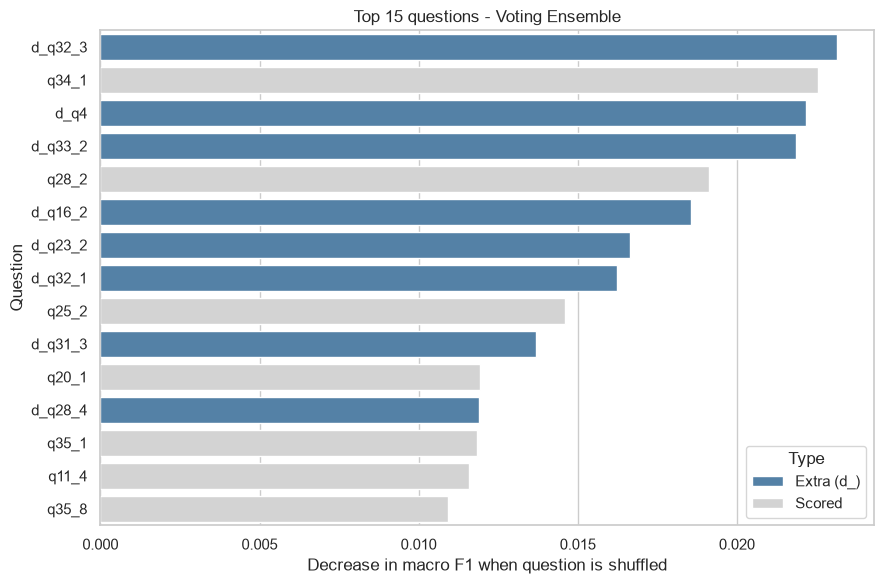

Extra (d_) questions in the top 15: 8


In [58]:
X_imp, _, y_imp, _ = train_test_split(
    X_test, y_test,
    train_size=10_000,
    random_state=RANDOM_STATE,
    stratify=y_test
)

start = time.time()
importance = permutation_importance(
    best_model,
    X_imp,
    y_imp,
    scoring="f1_macro",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=2   # kept low so large ensembles aren't copied to every CPU core at once
)
print(f"Permutation importance took {time.time() - start:.0f}s")

importance_df = pd.DataFrame({
    "Question": X_imp.columns,
    "Importance": importance.importances_mean,
    "Type": ["Extra (d_)" if c.startswith("d_") else "Scored" for c in X_imp.columns]
}).sort_values(by="Importance", ascending=False)

top_features = importance_df.head(15)

plt.figure(figsize=(9, 6))
sns.barplot(data=top_features, x="Importance", y="Question", hue="Type",
            dodge=False, palette={"Extra (d_)": "steelblue", "Scored": "lightgray"})
plt.title(f"Top 15 questions - {best_name}")
plt.xlabel("Decrease in macro F1 when question is shuffled")
plt.ylabel("Question")
plt.tight_layout()
plt.show()

print("Extra (d_) questions in the top 15:", (top_features["Type"] == "Extra (d_)").sum())

**Result:** 8 of the 15 most important questions are extra (`d_`) questions, even though they are only 37 of the 132 features. This matches Section 9a: the questions native speakers disagree on drive most of the model's ability to identify native language.

### Language signatures from logistic regression
Logistic regression learns one weight per question per language. A large positive weight means answering that question in the native-majority way makes that language **more** likely; a large negative weight means a "non-native" answer on that question points toward that language. Below are the three most telling questions in each direction for each language.

In [59]:
lr = final_models["Logistic Regression"]
coef = pd.DataFrame(lr.coef_, index=lr.classes_, columns=X_train.columns)

signatures = pd.DataFrame({
    "Most negative (non-native answer points here)": coef.apply(lambda r: ", ".join(r.nsmallest(3).index), axis=1),
    "Most positive (native-like answer points here)": coef.apply(lambda r: ", ".join(r.nlargest(3).index), axis=1)
})
display(signatures)

,Most negative (non-native answer points here),Most positive (native-like answer points here)
Dutch,"q26_3, d_q28_4, q3","d_q32_3, q35_1, q27_4"
Finnish,"q28_2, q25_4, q28_1","q34_1, q20_1, q27_1"
German,"q18_2, q3, q20_2","q25_4, q22_2, q35_1"
Hungarian,"q28_1, q20_1, q19_2","q25_2, q26_2, q30_3"
Polish,"q20_1, q24_3, d_q4","q20_3, q28_2, d_q32_4"
Portuguese,"q16_4, q35_4, q27_1","q14_3, q27_2, q25_1"
Russian,"q34_1, d_q4, q25_4","q28_2, q13_4, q23_3"
Spanish,"q20_1, d_q16_2, q11_3","q28_2, q19_2, q34_3"
Swedish,"q28_2, q19_4, q26_2","q31_1, q11_4, q24_2"
Turkish,"q35_8, q26_4, q24_1","q28_2, q26_3, q10_4"


**Result:** Each language has its own set of telling questions, and the extra (`d_`) questions appear for several languages (e.g. Dutch, Polish, Russian, Spanish). These coefficient patterns show that the model is not just measuring skill; specific questions point toward specific languages.

## 13. Extension: Predicting Language Family
The confusion matrix shows which individual languages get mixed up. Here we ask a broader question: can the model at least tell which **language family** a learner comes from? We group the 10 languages into 5 families and retrain the tuned gradient boosting model (one of the two strongest single models, and faster to retrain than the ensemble).

native_lang
Uralic      49437
Germanic    46775
Slavic      32977
Turkic      28856
Romance     20585
Name: count, dtype: int64

Family baseline (most frequent) accuracy: 0.277
Family accuracy: 0.643 | macro F1: 0.634


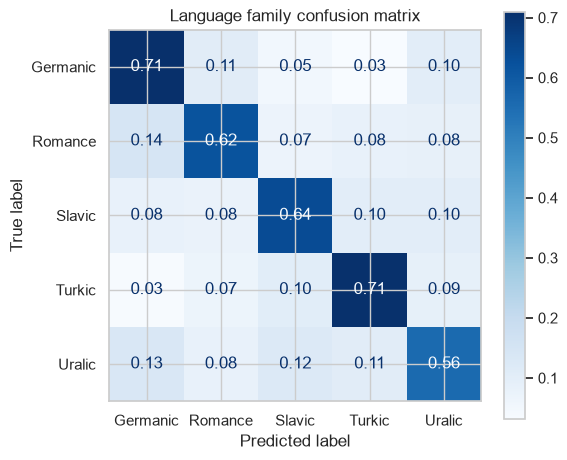

In [60]:
family = {
    "Finnish": "Uralic", "Hungarian": "Uralic",
    "Turkish": "Turkic",
    "German": "Germanic", "Dutch": "Germanic", "Swedish": "Germanic",
    "Russian": "Slavic", "Polish": "Slavic",
    "Spanish": "Romance", "Portuguese": "Romance"
}
yf_train, yf_test = y_train.map(family), y_test.map(family)
print(yf_train.value_counts())

family_model = clone(best_models["Gradient Boosting"]).fit(X_train, yf_train)
family_pred = family_model.predict(X_test)

family_baseline = yf_test.value_counts(normalize=True).max()
print(f"\nFamily baseline (most frequent) accuracy: {family_baseline:.3f}")
print(f"Family accuracy: {accuracy_score(yf_test, family_pred):.3f} | macro F1: {f1_score(yf_test, family_pred, average='macro'):.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    yf_test, family_pred, normalize="true", values_format=".2f", cmap="Blues", ax=ax)
ax.set_title("Language family confusion matrix")
plt.tight_layout()
plt.show()

**Result:** Predicting the language family is easier: 64.3% accuracy and 0.634 macro F1, against a 27.7% baseline. Combined with the confusion matrix, this shows that much of the remaining error is between closely related languages.

## 13b. Follow-up: Only Languages with More Than 20,000 Learners
To see how much the number of (and similarity between) languages affects performance, we repeat the task using only the five languages with more than 20,000 learners: Finnish, Turkish, German, Russian, and Hungarian. We filter the existing train/test split, so the same learners are used, and retrain the tuned gradient boosting model and the voting ensemble.

Languages kept: ['Finnish', 'Turkish', 'German', 'Russian', 'Hungarian']
Training rows: 115961 | Test rows: 28991
Baseline (most frequent) accuracy: 0.274

Gradient Boosting: accuracy 0.692 | macro F1 0.678
Voting Ensemble: accuracy 0.696 | macro F1 0.680


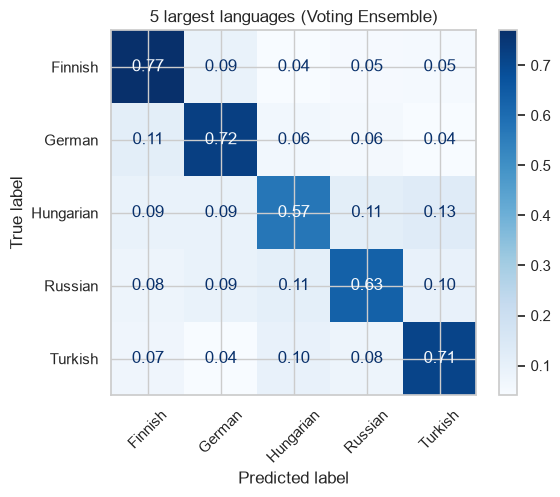

In [61]:
big = y.value_counts()[lambda s: s > 20_000].index.tolist()
print("Languages kept:", big)

tr, te = y_train.isin(big), y_test.isin(big)
Xb_train, yb_train = X_train[tr], y_train[tr]
Xb_test, yb_test = X_test[te], y_test[te]
print(f"Training rows: {len(Xb_train)} | Test rows: {len(Xb_test)}")

big_baseline = yb_test.value_counts(normalize=True).max()
print(f"Baseline (most frequent) accuracy: {big_baseline:.3f}\n")

big_models = {
    "Gradient Boosting": clone(best_models["Gradient Boosting"]),
    "Voting Ensemble": VotingClassifier(
        estimators=[(name, clone(best_models[name])) for name in top3],
        voting="soft", n_jobs=-1),
}
for name, model in big_models.items():
    model.fit(Xb_train, yb_train)
    p = model.predict(Xb_test)
    print(f"{name}: accuracy {accuracy_score(yb_test, p):.3f} | macro F1 {f1_score(yb_test, p, average='macro'):.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    yb_test, big_models["Voting Ensemble"].predict(Xb_test),
    normalize="true", values_format=".2f", cmap="Blues", ax=ax, xticks_rotation=45)
ax.set_title("5 largest languages (Voting Ensemble)")
plt.tight_layout(); plt.show()

**Result:** With only the five languages that have more than 20,000 learners, the voting ensemble reaches 69.6% accuracy and 0.680 macro F1 (baseline 27.4%), compared with 55.8% and 0.531 for all ten languages. Most of this gain comes from the easier task: there are fewer classes, and the closely related pairs that caused the most confusion (Dutch/German, Spanish/Portuguese, Polish/Russian) are no longer both present. Relative to its baseline, the ten-language model performs about as well or better (about 3.1× vs. 2.5× the baseline accuracy), so the higher score mainly reflects a simpler question rather than a stronger model.

## 14. Summary
- **Every model clearly beats the baseline**, so grammar answers do carry information about a learner's native language. Always guessing Finnish gets 17.8% accuracy and 0.030 macro F1; random guessing among 10 languages would get about 10%.
- **Best model:** the soft-voting ensemble (MLP + gradient boosting + logistic regression), with **macro F1 of 0.531** and **accuracy of 55.8%** on the test set. The MLP alone (0.527) and gradient boosting alone (0.523) were close behind, so ensembling added only a small gain. Naive Bayes was the weakest model (0.396), likely because it assumes every question is independent given the language.
- **The 37 extra questions matter most.** Adding the grammar decisions that native speakers disagree on raised macro F1 from 0.380 to 0.494 for logistic regression and from 0.397 to 0.523 for gradient boosting. 12 of the 20 questions that differ most between languages, and 8 of the 15 most important questions for the best model, are extra (`d_`) questions. These items reflect usage and dialect rather than clear right/wrong grammar, so learners' answers on them carry traces of their first language.
- **Adding skill information did not help** (Section 9b): adding the overall score or skill-adjusting the answers changed cross-validated macro F1 by less than 0.01, so the models already account for overall skill.
- **Confusions follow language families.** The most common mix-ups were Portuguese → Spanish (16%), Dutch ↔ German (13%), Polish → Russian (12%), and Swedish → Dutch (11%). Turkish (F1 0.667) and Finnish (0.658) were easiest to identify; Portuguese (0.418) and Spanish (0.437) were hardest, since they are the smallest classes and are mostly confused with each other.
- **Language family is easier to predict:** grouping the 10 languages into 5 families gives 64.3% accuracy and 0.634 macro F1 (baseline 27.7%).
- **Fewer, less similar languages are easier:** using only the five languages with more than 20,000 learners raises accuracy to 69.6% and macro F1 to 0.680 (baseline 27.4%), mainly because related language pairs are removed.
- **Limitation:** accuracy falls from 64% for the lowest-scoring quarter of learners to 47% for the top quarter (macro F1 0.58 → 0.38), because near-native learners make few mistakes for the model to use.